In [20]:
#DMV-1 : CSV, Excel, JSON - Analyzing Sales Data from Multiple File Formats

import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt
import seaborn as sns

In [21]:
# Step 1: Create CSV dataset
csv_data = {
    'Transaction_ID': [101, 102, 103, 104, 105, 105],
    'Product': ['Laptop', 'Mouse', 'Monitor', 'Keyboard', 'Laptop', 'Laptop'],
    'Price': [1200, 25, 300, 80, 1200, 1200],
    'Quantity': [1, 2, np.nan, 1, 1, 1],
    'Date': ['2023-10-01', '2023-10-01', '2023-10-02',
             '2023-10-03', '2023-10-04', '2023-10-04']
}

pd.DataFrame(csv_data).to_csv('sales_data.csv', index=False)

In [22]:
# Step 2: Create Excel dataset
excel_data = {
    'Transaction_ID': [106, 107, 108],
    'Product': ['mouse', 'Tablet', 'Monitor'],
    'Price': [25, 450, 300],
    'Quantity': [5, 1, 2],
    'Date': ['2023-10-05', '2023-10-06', '2023-10-07']
}

pd.DataFrame(excel_data).to_excel('sales_data.xlsx', index=False)

In [23]:
# Step 3: Create JSON dataset
json_data = [
    {'Transaction_ID': 109, 'Product': 'Keyboard',
     'Price': 80, 'Quantity': 3, 'Date': '2023-10-08'},
    {'Transaction_ID': 110, 'Product': 'Laptop',
     'Price': 1200, 'Quantity': 1, 'Date': '2023-10-09'}
]

In [24]:
with open('sales_data.json', 'w') as f:
    json.dump(json_data, f)

print("Sample files created successfully!")

Sample files created successfully!


In [25]:
# Step 4: Load datasets
df_csv = pd.read_csv('sales_data.csv')
df_excel = pd.read_excel('sales_data.xlsx')
df_json = pd.read_json('sales_data.json')

In [26]:
# Step 5: Explore datasets
print("\nCSV Data:")
print(df_csv.head())
df_csv.info()


CSV Data:
   Transaction_ID   Product  Price  Quantity        Date
0             101    Laptop   1200       1.0  2023-10-01
1             102     Mouse     25       2.0  2023-10-01
2             103   Monitor    300       NaN  2023-10-02
3             104  Keyboard     80       1.0  2023-10-03
4             105    Laptop   1200       1.0  2023-10-04
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Transaction_ID  6 non-null      int64  
 1   Product         6 non-null      object 
 2   Price           6 non-null      int64  
 3   Quantity        5 non-null      float64
 4   Date            6 non-null      object 
dtypes: float64(1), int64(2), object(2)
memory usage: 372.0+ bytes


In [27]:
print("\nExcel Data:")
print(df_excel.head())
df_excel.info()


Excel Data:
   Transaction_ID  Product  Price  Quantity        Date
0             106    mouse     25         5  2023-10-05
1             107   Tablet    450         1  2023-10-06
2             108  Monitor    300         2  2023-10-07
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Transaction_ID  3 non-null      int64 
 1   Product         3 non-null      object
 2   Price           3 non-null      int64 
 3   Quantity        3 non-null      int64 
 4   Date            3 non-null      object
dtypes: int64(3), object(2)
memory usage: 252.0+ bytes


In [28]:
print("\nJSON Data:")
print(df_json.head())
df_json.info()


JSON Data:
   Transaction_ID   Product  Price  Quantity       Date
0             109  Keyboard     80         3 2023-10-08
1             110    Laptop   1200         1 2023-10-09
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Transaction_ID  2 non-null      int64         
 1   Product         2 non-null      object        
 2   Price           2 non-null      int64         
 3   Quantity        2 non-null      int64         
 4   Date            2 non-null      datetime64[ns]
dtypes: datetime64[ns](1), int64(3), object(1)
memory usage: 212.0+ bytes


In [29]:
# Step 6: Combine datasets
df = pd.concat([df_csv, df_excel, df_json],
               ignore_index=True)

In [30]:
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
Transaction_ID    0
Product           0
Price             0
Quantity          1
Date              0
dtype: int64


In [31]:
# Step 7: Clean data
df = df.drop_duplicates().copy()
df['Quantity'] = df['Quantity'].fillna(1)
df['Product'] = df['Product'].str.capitalize()
df['Date'] = pd.to_datetime(df['Date'])

In [32]:
# Step 8: Calculate revenue
df['Total_Revenue'] = df['Price'] * df['Quantity']

In [33]:
print("\nCleaned Dataset:")
print(df)


Cleaned Dataset:
    Transaction_ID   Product  Price  Quantity       Date  Total_Revenue
0              101    Laptop   1200       1.0 2023-10-01         1200.0
1              102     Mouse     25       2.0 2023-10-01           50.0
2              103   Monitor    300       1.0 2023-10-02          300.0
3              104  Keyboard     80       1.0 2023-10-03           80.0
4              105    Laptop   1200       1.0 2023-10-04         1200.0
6              106     Mouse     25       5.0 2023-10-05          125.0
7              107    Tablet    450       1.0 2023-10-06          450.0
8              108   Monitor    300       2.0 2023-10-07          600.0
9              109  Keyboard     80       3.0 2023-10-08          240.0
10             110    Laptop   1200       1.0 2023-10-09         1200.0


In [34]:
# Step 9: Sales analysis
total_sales = df['Total_Revenue'].sum()
avg_sales = df['Total_Revenue'].mean()

product_sales = df.groupby('Product')['Total_Revenue'].sum().reset_index()

In [35]:
print("\nTotal Revenue:", total_sales)
print("Average Order Value:", avg_sales)


Total Revenue: 5445.0
Average Order Value: 544.5


In [36]:
print("\nProduct-wise Sales:")
print(product_sales)


Product-wise Sales:
    Product  Total_Revenue
0  Keyboard          320.0
1    Laptop         3600.0
2   Monitor          900.0
3     Mouse          175.0
4    Tablet          450.0


Text(0, 0.5, 'Revenue')

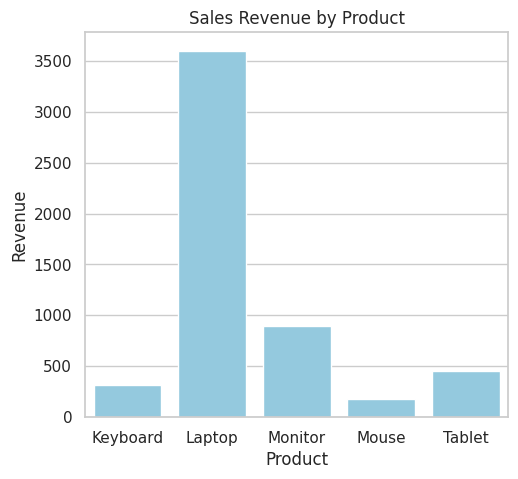

In [37]:
# Step 10: Visualization
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 5))
# Bar Chart
plt.subplot(1, 2, 1)
sns.barplot(data=product_sales, x='Product',
            y='Total_Revenue', color='skyblue')
plt.title('Sales Revenue by Product')
plt.xlabel('Product')
plt.ylabel('Revenue')

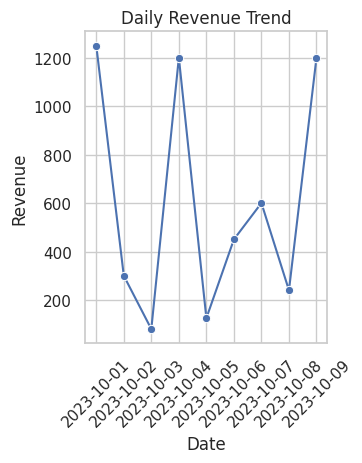

In [38]:
# Line Chart
plt.subplot(1, 2, 2)
daily_sales = df.groupby('Date')['Total_Revenue'].sum().reset_index()
sns.lineplot(data=daily_sales, x='Date',
             y='Total_Revenue', marker='o')
plt.title('Daily Revenue Trend')
plt.xlabel('Date')
plt.ylabel('Revenue')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()